# The Random Forest Rangers — Modeling

German Accident Atlas 2025 · Presentation: 23 October 2026

**File 2 of 2.** We compare probability predictions and explain what the results mean. Detailed exploration is in `01_accident_detailed_EDA.ipynb`.

Run from the project folder containing `data/`. This notebook works in a fresh Python session: it does not depend on running the EDA notebook first. All code cells were executed on the uploaded updated dataset. Saved outputs include the actual baselines, models, training-only searches and validation-based model choice. The final test remains reserved.

## The Machine Learning Workflow

### Define the Business Goal

**Suggested client:** a local or regional road-safety planning team. This is a proposed audience, not a confirmed client.

**Question:** Given that an injury accident has happened, how likely is it to involve serious or fatal injuries, based on the place, time, road conditions, lighting and road users involved?

The answer could help a road-safety team identify situations that deserve closer investigation. It cannot tell them where the next accident will happen or which change would prevent injuries.

Our answer is a probability, such as 20 out of 100 similar injury accidents. `severe = 0` means slight injury; `severe = 1` means serious or fatal injury. We do not use accident type, accident kind, IDs or administrative fields as prediction inputs. Federal state is retained as the agreed location input.

We have not agreed a minimum useful improvement or a decision threshold with a client. A better score alone does not prove the tool is ready for use.

### Get the Data

Use only `data/accidents_2025_with_population.csv`. The agreed version has 272,812 rows and 41 columns. Each row is one recorded injury accident. Keep municipality codes (`ags`) and accident IDs as text to preserve their format.

In [98]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_FILE = Path("data/accidents_2025_with_population.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_FILE}. Open notebook from the ML_project folder, "
        "or update DATA_FILE to the correct path."
    )

df = pd.read_csv(DATA_FILE, dtype={"ags": str, "accident_id": str})
print("Dataset shape:", df.shape)
print("Unique IDs:", df["accident_id"].nunique())
print("Duplicate IDs:", df["accident_id"].duplicated().sum())
assert df["accident_id"].is_unique
assert set(df["severe"].dropna().unique()) == {0, 1}

Dataset shape: (272812, 41)
Unique IDs: 272812
Duplicate IDs: 0


### First Look at the Data

Check the injury labels, count the outcomes and look for missing population information. Population density describes a whole municipality, not the exact road where an accident happened.

In [99]:
city_features = ["population", "area_km2", "population_per_km2"]

print("Severity categories and binary target:")
display(pd.crosstab(df["severity"], df["severe"], dropna=False))
print("\nBinary target counts:")
print(df["severe"].value_counts())
print("\nMissing city values:")
print(df[city_features].isna().sum())

assert not df[city_features].isna().any().any(), "Unexpected missing city values"
assert len(df) == 272812, "Dataset size differs from the agreed cleaned version"

Severity categories and binary target:


severe,0,1
severity,,
Accident with persons killed,0,2474
Accident with seriously injured,0,40371
Accident with slightly injured,229967,0



Binary target counts:
severe
0    229967
1     42845
Name: count, dtype: int64

Missing city values:
population            0
area_km2              0
population_per_km2    0
dtype: int64


## Clean the Data

The updated file was already prepared: 195 rows without municipality information were removed before this notebook. We do not remove them again or repeat earlier cleaning on an older file.

We check the agreed size, unique IDs, complete target, population values and injury labels. A failed check asks us to investigate; it does not silently change the data. Any calculation learned from the data, such as scaling values for a model, will use training rows only.

In [100]:
assert df.shape == (272812, 41), "Use the agreed updated dataset"
assert df["severe"].notna().all()
assert df["ags"].notna().all()
assert df["accident_id"].notna().all()
assert df["severe"].value_counts().to_dict() == {0: 229967, 1: 42845}
assert (df["population"] >= 0).all()
assert (df["area_km2"] > 0).all()
assert (df["population_per_km2"] >= 0).all()
print("The agreed data checks passed. No extra rows were removed.")

The agreed data checks passed. No extra rows were removed.


## Train-Validation-Test Split

We keep the agreed shuffled 70/15/15 split, using seed 42. Each part has nearly the same share of serious/fatal accidents. Training teaches the models; validation compares them; test is reserved for one final check after all choices are fixed.

Expected sizes: 190,968 training rows, 40,922 validation rows and 40,922 test rows. A teammate who split using the three original injury labels may have different accidents in each part, so their scores are not directly comparable.

In [101]:
from sklearn.model_selection import train_test_split

train, temporary = train_test_split(
    df, test_size=0.30, stratify=df["severe"], random_state=42
)
validation, test = train_test_split(
    temporary, test_size=0.50, stratify=temporary["severe"], random_state=42
)

# The test set is used only to verify that the split contains each ID once.
all_ids = pd.concat([train["accident_id"], validation["accident_id"], test["accident_id"]])
assert len(all_ids) == len(df)
assert all_ids.is_unique
assert set(all_ids) == set(df["accident_id"])

print("Training:", len(train), "| Validation:", len(validation), "| Test:", len(test))
print("\nSevere percentage (training and validation):")
display(pd.DataFrame({
    "split": ["train", "validation"],
    "accidents": [len(train), len(validation)],
    "severe_pct": [100 * train["severe"].mean(), 100 * validation["severe"].mean()]
}).round(2))

Training: 190968 | Validation: 40922 | Test: 40922

Severe percentage (training and validation):


,split,accidents,severe_pct
0,train,190968,15.70
1,validation,40922,15.71


### Keep the same accidents in each split

Both notebooks use the same file order, seed and splitting rules. If saved split files exist, verify their IDs against these groups. Do not overwrite a different split without checking why it differs. This check reads test IDs only, never test performance.

In [102]:
assert (len(train), len(validation), len(test)) == (190968, 40922, 40922)
split_dir = Path("data/splits_updated")
for name, part in [("train", train), ("validation", validation), ("test", test)]:
    candidates = [split_dir / f"{name}.csv", split_dir / f"{name}.csv.gz"]
    if name == "validation":
        candidates += [split_dir / "val.csv", split_dir / "val.csv.gz"]
    for saved_path in candidates:
        if saved_path.exists():
            saved_ids = pd.read_csv(saved_path, usecols=["accident_id"], dtype={"accident_id": str})
            assert saved_ids["accident_id"].is_unique
            assert set(saved_ids["accident_id"]) == set(part["accident_id"]), f"Split differs: {saved_path}"
            print(f"Verified IDs: {saved_path}")
print("Splits are ready. No files were overwritten.")

Verified IDs: data/splits_updated/train.csv.gz
Verified IDs: data/splits_updated/val.csv.gz
Verified IDs: data/splits_updated/test.csv.gz
Splits are ready. No files were overwritten.


## Explore the Training Data — Findings Used Here

The full exploration is in the EDA file. It covers injury severity, month and season, weekdays and weekends, hour and night, lighting, road surfaces, all six road-user groups, states and geography, road-user combinations, and municipality density.

The density findings suggest that population density adds useful information, so every model in this notebook uses it as an input.

## Feature Engineering

We use state, weekday, lighting, road condition, longitude, latitude, cyclic hour and month (sine and cosine), six road-user flags and municipality population density.

**Cyclic time:** hour and month repeat in a circle, so 23:00 is next to 00:00 and December is next to January. As plain numbers (0–23, 1–12), a model would treat them as far apart. We turn each into a sine and a cosine column, which places them on a circle. These are fixed formulas, not learned from the data, so they cannot leak information between splits. We exclude the answer itself and fields that would reveal the outcome or do not fit the agreed use.

The next cell creates the input tables. Later, each model learns its preparation steps from training data only. Weekend and nighttime labels for the historical baseline use fixed rules.

### Pick the inputs

We use **17 inputs**: state, weekday, lighting, road condition, longitude, latitude, `hour_sin`, `hour_cos`, `month_sin`, `month_cos`, six road-user indicators and municipality population density.

The original `hour` column stays in the data because the historical baseline and the error analysis use it to label night and day. It is not a model input.

We check the column names and missing values before training.

In [103]:
# Cyclic time: puts 23:00 next to 00:00 and December next to January
train, validation, test = train.copy(), validation.copy(), test.copy()
for frame in (train, validation, test):
    frame["hour_sin"] = np.sin(2 * np.pi * frame["hour"] / 24)
    frame["hour_cos"] = np.cos(2 * np.pi * frame["hour"] / 24)
    frame["month_sin"] = np.sin(2 * np.pi * (frame["month"] - 1) / 12)
    frame["month_cos"] = np.cos(2 * np.pi * (frame["month"] - 1) / 12)

categorical_features = ["state", "weekday", "light", "road_condition"]
numeric_features = ["longitude", "latitude", "hour_sin", "hour_cos", "month_sin", "month_cos"]
binary_features = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle"]
base_features = categorical_features + numeric_features + binary_features
features_with_density = base_features + ["population_per_km2"]

forbidden = {"accident_id", "severity", "severe", "killed", "accident_kind", "accident_type",
             "ags", "location_check", "date_check", "n_participant_types", "participants"}
assert not (set(features_with_density) & forbidden)
assert set(features_with_density).issubset(train.columns)
assert set(features_with_density).issubset(validation.columns)
assert train[features_with_density].isna().sum().sum() == 0, "Handle missing training features before modeling"
assert validation[features_with_density].isna().sum().sum() == 0, "Handle missing validation features before modeling"

X_train_density = train[features_with_density].copy()
X_val_density = validation[features_with_density].copy()
y_train = train["severe"]
y_val = validation["severe"]
print("Features:", features_with_density)
print("Feature count:", len(features_with_density))

Features: ['state', 'weekday', 'light', 'road_condition', 'longitude', 'latitude', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'bicycle', 'car', 'pedestrian', 'motorcycle', 'truck', 'other_vehicle', 'population_per_km2']
Feature count: 17


### Define weekend labels

We use the same weekday names as the EDA notebook. Unknown labels stop the historical baseline so they cannot silently be treated as weekdays.

In [104]:
weekend_names = {"saturday", "sunday", "samstag", "sonntag", "sat", "sun"}
weekday_names = {
    "monday", "tuesday", "wednesday", "thursday", "friday",
    "montag", "dienstag", "mittwoch", "donnerstag", "freitag",
    "mon", "tue", "wed", "thu", "fri",
}

## Baseline Model

A baseline is a simple prediction to beat. We use two: the overall training severe rate and the severe rate for similar training scenarios. Both are checked on the same validation rows as the fitted models.

## Constant probability baseline

Our simplest prediction gives every validation accident the **same probability: the severe share in training**. A useful model should improve on this starting point.

AP and ROC-AUC are better when higher; Brier (average squared probability error) is better when lower. Constant predictions have ROC-AUC 0.5 and AP equal to the validation severe share.

In [105]:
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

y_train = train["severe"]
y_val = validation["severe"]
training_severe_rate = float(y_train.mean())
p_constant = np.full(len(validation), training_severe_rate)

def validation_scores(name, probabilities):
    probabilities = np.asarray(probabilities, dtype=float)
    assert probabilities.shape == (len(y_val),)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    return {
        "model": name,
        "AP": average_precision_score(y_val, probabilities),
        "ROC_AUC": roc_auc_score(y_val, probabilities),
        "Brier": brier_score_loss(y_val, probabilities),
    }

constant_results = pd.DataFrame([validation_scores("Constant probability", p_constant)])
print(f"Probability learned from training: {training_severe_rate:.2%}")
display(constant_results.round(5))

Probability learned from training: 15.70%


,model,AP,ROC_AUC,Brier
0,Constant probability,0.15705,0.5,0.13239


## Historical scenario baseline

We group training accidents by **federal state, night (22:00–05:59), weekend and the exact combination of all six road-user flags**. For example, car + bicycle differs from car only. These definitions match this notebook's EDA; exact equivalence to the earlier notebook has not been checked.

Each group predicts its severe share, smoothed with strength **100**:

`probability = (group severe count + 100 × overall training rate) / (group accident count + 100)`

Think of this as adding 100 example accidents with the overall training rate. Small groups receive more help; large groups rely more on their own observations. Unseen validation groups use the overall training rate. Only training labels build the lookup table. “Historical” here means the training sample from 2025, not earlier years.

In [106]:
scenario_road_users = ["car", "bicycle", "pedestrian", "motorcycle", "truck", "other_vehicle"]
scenario_columns = ["state", "nighttime", "weekend"] + scenario_road_users

def make_scenario_keys(frame):
    required = ["state", "hour", "weekday"] + scenario_road_users
    assert not frame[required].isna().any().any(), "Missing scenario inputs"
    assert frame["hour"].isin(range(24)).all(), "Unexpected hour values"
    assert frame[scenario_road_users].isin([0, 1]).all().all(), "Expected binary road-user flags"
    days = frame["weekday"].astype(str).str.strip().str.lower()
    unknown = set(days.unique()) - (weekend_names | weekday_names)
    assert not unknown, f"Verify weekday labels first: {unknown}"
    keys = frame[["state"] + scenario_road_users].copy()
    keys["nighttime"] = ((frame["hour"] >= 22) | (frame["hour"] < 6)).astype(int)
    keys["weekend"] = days.isin(weekend_names).astype(int)
    return keys[scenario_columns]

scenario_train = make_scenario_keys(train)
scenario_validation = make_scenario_keys(validation)
scenario_rates = (
    scenario_train.assign(severe=y_train)
    .groupby(scenario_columns, observed=True)["severe"]
    .agg(accidents="size", severe_count="sum")
)
smoothing_strength = 100
scenario_rates["probability"] = (
    scenario_rates["severe_count"] + smoothing_strength * training_severe_rate
) / (scenario_rates["accidents"] + smoothing_strength)

# Reindex keeps the exact validation row order, including repeated scenarios.
validation_keys = pd.MultiIndex.from_frame(scenario_validation)
matched_rates = scenario_rates["probability"].reindex(validation_keys)
unseen_scenarios = matched_rates.isna().to_numpy()
p_historical = matched_rates.fillna(training_severe_rate).to_numpy()

baseline_results = pd.DataFrame([
    validation_scores("Constant probability", p_constant),
    validation_scores("Historical scenario", p_historical),
])
print(f"Training scenarios: {len(scenario_rates):,}")
print(f"Validation accidents using fallback: {unseen_scenarios.sum():,} ({unseen_scenarios.mean():.2%})")
display(baseline_results.round(5))

Training scenarios: 1,305
Validation accidents using fallback: 57 (0.14%)


,model,AP,ROC_AUC,Brier
0,Constant probability,0.15705,0.50000,0.13239
1,Historical scenario,0.22556,0.62163,0.12916


**How to read the result:** Higher AP/AUC than the constant baseline means the scenario groups help rank severe accidents. Lower Brier means better probability predictions overall. Brier alone does not establish good calibration. We keep smoothing at 100 and leave the test set untouched.

## Train the Model

We use three methods, each with population density as an input. Logistic Regression learns a smooth relationship between the inputs and the probability. Random Forest combines many decision trees, allowing more complicated patterns. Gradient Boosting builds trees in sequence to improve the predictions step by step.

We keep all existing model settings. We do not rebalance or duplicate the classes here: the goal is to estimate probabilities for the observed accident mix. We avoid relying on accuracy because most accidents have slight injuries.

## Logistic Regression — with population density

Logistic Regression is a simple machine-learning model that learns from past accidents and gives a **probability** for a new accident scenario.

The model uses time, state, coordinates, lighting, road condition, road users and municipality population density. We do not use the outcome, accident kind/type, accident IDs or administrative fields to predict severity.

### Train the model

The model needs numbers to work with. We turn words such as state names into number-based columns and put numerical inputs on comparable scales.

For density, we first use `log(1 + density)` so very large values do not dominate. The model learns **only from training data**. We check its predicted probabilities on **validation data**.

In [107]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

density_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numeric", StandardScaler(), numeric_features),
    ("road_users", "passthrough", binary_features),
    ("density", Pipeline([
        ("log", FunctionTransformer(np.log1p, validate=False)),
        ("scale", StandardScaler()),
    ]), ["population_per_km2"]),
])

lr_density = Pipeline([
    ("prep", density_preprocessor),
    ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)),
])

lr_density.fit(X_train_density, y_train)

p_density = lr_density.predict_proba(X_val_density)[:, 1]
print("Model trained. Only validation probabilities were generated.")

Model trained. Only validation probabilities were generated.


### Check the model on validation data

We use three scores:

- **Average Precision (AP):** Does the model tend to rank truly severe accidents higher? **Higher is better.**
- **ROC-AUC:** How well does it separate the two injury groups? **Higher is better.**
- **Brier:** How far off are its probability predictions? **Lower is better.**

We are comparing probabilities here, so we do not need to choose a yes/no threshold yet.

In [108]:
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

comparison = pd.DataFrame([
    {
        "model": "LR — With density",
        "AP": average_precision_score(y_val, p_density),
        "ROC_AUC": roc_auc_score(y_val, p_density),
        "Brier": brier_score_loss(y_val, p_density),
    }
])
display(comparison.round(5))

,model,AP,ROC_AUC,Brier
0,LR — With density,0.2594,0.65602,0.12681


## Random Forest — Try a different kind of model

Random Forest combines lots of decision trees. Unlike basic Logistic Regression, it can discover more complicated patterns without us spelling them out.

We train **one forest** with the same inputs, including population density. That lets us compare the **algorithm** (Logistic Regression versus Random Forest). We still don't touch the final test set.

### Train the forest

We use **200 trees**, limit them to **15 levels**, and require at least **50 accidents in a leaf**. These limits help avoid overly specific patterns; they are starting settings, not proven best values.

The forest learns from the training accidents only.

In [109]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Random Forest settings
rf_settings = {
    "n_estimators": 200,
    "min_samples_leaf": 50,
    "max_depth": 15,
    "random_state": 42,
    "n_jobs": -1
}

# Random Forest with population density
rf_density_pipeline = Pipeline([
    ("preprocessor", clone(density_preprocessor)),
    ("model", RandomForestClassifier(**rf_settings))
])

# Fit using training data only
rf_density_pipeline.fit(X_train_density, train["severe"])

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### Check the forest on validation data

Training a model is not enough — we must see how it performs on accidents it did not learn from. We calculate the same three scores as for Logistic Regression.

In [110]:
# Predict probabilities for validation accidents only
p_rf_density = rf_density_pipeline.predict_proba(X_val_density)[:, 1]

# Keep the fitted-model results; add the benchmarks in the next comparison section
rf_results = pd.DataFrame([
    {
        "model": "RF — With density",
        "AP": average_precision_score(y_val, p_rf_density),
        "ROC_AUC": roc_auc_score(y_val, p_rf_density),
        "Brier": brier_score_loss(y_val, p_rf_density),
    }
])
all_model_results = pd.concat([comparison, rf_results], ignore_index=True)

display(all_model_results.round(5))

,model,AP,ROC_AUC,Brier
0,LR — With density,0.25940,0.65602,0.12681
1,RF — With density,0.26847,0.66733,0.12614


### Is the forest learning too much from training accidents?

A forest can do very well on accidents it has already seen but worse on new ones. We compare **training and validation** to look for that gap. If the training scores are much better, we should be careful about overfitting.

In [111]:
rf_gap_rows = []
for name, model, X_train, X_val in [
    ("RF — With density", rf_density_pipeline, X_train_density, X_val_density),
]:
    for part, y_true, X in [
        ("Training", y_train, X_train),
        ("Validation", y_val, X_val),
    ]:
        probabilities = model.predict_proba(X)[:, 1]
        rf_gap_rows.append({
            "model": name,
            "split": part,
            "AP": average_precision_score(y_true, probabilities),
            "ROC_AUC": roc_auc_score(y_true, probabilities),
            "Brier": brier_score_loss(y_true, probabilities),
        })
rf_gap_summary = pd.DataFrame(rf_gap_rows)
display(rf_gap_summary.round(5))

,model,split,AP,ROC_AUC,Brier
0,RF — With density,Training,0.31202,0.70530,0.12356
1,RF — With density,Validation,0.26847,0.66733,0.12614


## Gradient Boosting — Our third algorithm

Random Forest combines trees built separately. Gradient Boosting builds trees one after another, with each new tree helping correct the remaining prediction errors. We use `HistGradientBoostingClassifier`, a version designed for larger tables.

We train it with the same accidents and input columns as the earlier models, including population density. We do not know whether it is better until we measure its validation results.

### Prepare the inputs and train the model

We reuse a copy of the existing preparation steps. Categories become separate number columns, and density keeps the same log-and-scale preparation. This model needs a regular, filled-out number table rather than a compressed table, so we convert the prepared inputs inside the pipeline.

The model uses **200 learning rounds**, a **0.05 learning rate**, at most **15 end groups per tree**, and at least **50 training accidents per end group**. These are starting settings, not tuned settings. We turn automatic early stopping off so the model uses all training rows and a fixed number of rounds. No validation or test labels are passed into training.

In [112]:
from sklearn.ensemble import HistGradientBoostingClassifier


def as_dense_table(values):
    """Convert a compressed table when needed; leave ordinary arrays unchanged."""
    return values.toarray() if hasattr(values, "toarray") else np.asarray(values)


gb_settings = {
    "max_iter": 200,
    "learning_rate": 0.05,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 50,
    "l2_regularization": 1.0,
    "early_stopping": False,
    "categorical_features": None,  # Categories are already one-hot encoded.
    "random_state": 42,
}

gb_density_pipeline = Pipeline([
    ("preprocessor", clone(density_preprocessor)),
    ("dense", FunctionTransformer(as_dense_table, validate=False)),
    ("model", HistGradientBoostingClassifier(**gb_settings)),
])

gb_density_pipeline.fit(X_train_density, y_train)
print("Gradient Boosting model trained using training data only.")

Gradient Boosting model trained using training data only.


### Check the model on validation accidents

We calculate probabilities and the same three scores as before. Higher AP and ROC-AUC are better; lower Brier means smaller probability errors.

In [113]:
p_gb_density = gb_density_pipeline.predict_proba(X_val_density)[:, 1]

gb_results = pd.DataFrame([
    validation_scores("GB — With density", p_gb_density),
])
display(gb_results.round(5))

,model,AP,ROC_AUC,Brier
0,GB — With density,0.27179,0.66836,0.12576


### Check the training-versus-validation gap

We compare predictions for accidents the model learned from with predictions for validation accidents. Much better training scores can be a sign that some learned details do not carry over. Training scores are an optimistic check, not independent evidence of performance.

In [114]:
gb_gap_rows = []
for name, fitted_model, training_inputs, validation_inputs in [
    ("GB — With density", gb_density_pipeline, X_train_density, X_val_density),
]:
    for split_name, targets, inputs in [
        ("Training", y_train, training_inputs),
        ("Validation", y_val, validation_inputs),
    ]:
        probabilities = fitted_model.predict_proba(inputs)[:, 1]
        gb_gap_rows.append({
            "model": name,
            "split": split_name,
            "AP": average_precision_score(targets, probabilities),
            "ROC_AUC": roc_auc_score(targets, probabilities),
            "Brier": brier_score_loss(targets, probabilities),
        })
gb_gap_summary = pd.DataFrame(gb_gap_rows)
display(gb_gap_summary.round(5))

,model,split,AP,ROC_AUC,Brier
0,GB — With density,Training,0.28273,0.67615,0.12504
1,GB — With density,Validation,0.27179,0.66836,0.12576


## Evaluate the Model

All comparisons below use validation data. We adapt the reference's evaluation section this way because our final test data must stay reserved.

**AP:** how well the model puts severe accidents near the top of the list. **ROC-AUC:** how well it ranks severe accidents above slight accidents. Higher is better for both. **Brier:** the average squared difference between probability and outcome; lower is better. Brier combines several aspects of prediction quality, so we also check whether predicted percentages match observed percentages.

## Initial comparison — five approaches before tuning

Every approach predicts the **same validation accidents**. AP and ROC-AUC measure ranking; Brier measures probability error. Compare all three before deciding which approach is useful. The constant baseline cannot rank accidents.

This initial table compares **three fitted models (all with population density) plus two baselines**. The later tuning section expands the comparison. GB means Gradient Boosting.

,model,AP,ROC_AUC,Brier
0,Constant probability,0.15705,0.50000,0.13239
1,Historical scenario,0.22556,0.62163,0.12916
2,LR — With density,0.25940,0.65602,0.12681
3,RF — With density,0.26847,0.66733,0.12614
4,GB — With density,0.27179,0.66836,0.12576


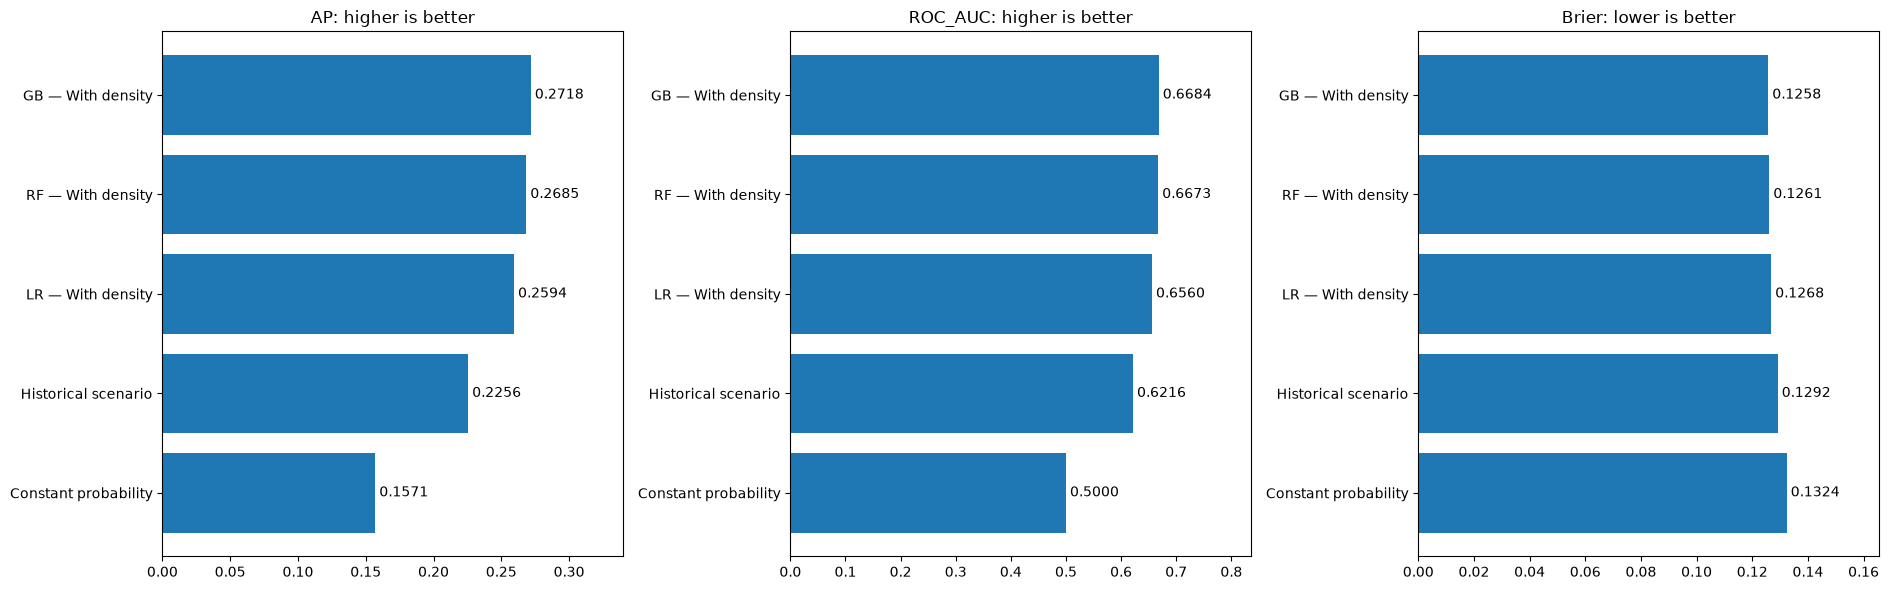

In [115]:
validation_predictions = {
    "Constant probability": p_constant,
    "Historical scenario": p_historical,
    "LR — With density": p_density,
    "RF — With density": p_rf_density,
    "GB — With density": p_gb_density,
}
all_model_results = pd.DataFrame([
    validation_scores(name, probabilities)
    for name, probabilities in validation_predictions.items()
])
assert len(all_model_results) == 5
display(all_model_results.round(5))
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, metric in zip(axes, ["AP", "ROC_AUC", "Brier"]):
    ax.barh(all_model_results["model"], all_model_results[metric])
    ax.set_title(f"{metric}: {'lower' if metric == 'Brier' else 'higher'} is better")
    for i, value in enumerate(all_model_results[metric]):
        ax.text(value, i, f" {value:.4f}", va="center")
    ax.set_xlim(0, all_model_results[metric].max() * 1.25)
plt.tight_layout()
plt.show()

### Logistic Regression and Random Forest visualization

This keeps the original Logistic Regression and Random Forest comparison (both with density). The five-approach chart above includes both benchmarks and Gradient Boosting.

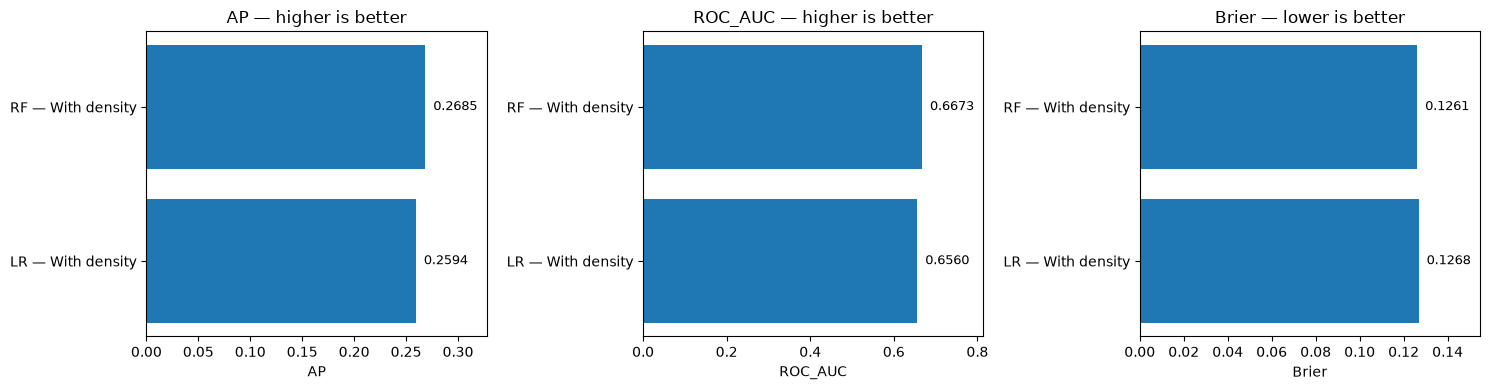

In [116]:
four_model_results = all_model_results.loc[all_model_results["model"].str.startswith(("LR", "RF"))].reset_index(drop=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["AP", "ROC_AUC", "Brier"]):
    ax.barh(four_model_results["model"], four_model_results[metric])
    ax.set_title(f"{metric} — {'lower' if metric == 'Brier' else 'higher'} is better")
    ax.set_xlabel(metric)
    for i, value in enumerate(four_model_results[metric]):
        ax.text(value, i, f"  {value:.4f}", va="center", fontsize=9)
    ax.set_xlim(0, four_model_results[metric].max() * 1.22)
plt.tight_layout()
plt.show()

### What we observed

- All three models beat both simple guesses on every score. Using the place, time, conditions, road users and density together tells us more than a single average or a lookup table.
- **Gradient Boosting (GB) is best on all three scores**: AP 0.272, ROC-AUC 0.668, Brier 0.1258. Random Forest is a close second and Logistic Regression is third.
- The gaps between the models are small. The biggest jump is from the simple guesses to any model, not from one model to another.

### What we do next

Good ranking scores don't prove that the predicted percentages are right. Next we check **calibration**: when a model says "20%", are about 20% of those accidents really serious?

## Check calibration and model limitations

**Calibration** asks: among accidents predicted to have about a 20% probability, were about 20% actually severe? Points close to the diagonal are better aligned. Each point groups similar validation predictions; this is a diagnostic, not a recalibration step.

The training-versus-validation tables for Random Forest and Gradient Boosting above check for overfitting. Better training scores are expected; a large gap suggests the model learned details that transfer poorly. These training scores are optimistic, not independent estimates.

Random splits can place accidents from the same municipality in both sets. This evaluates other accidents from a similar mixture, not unseen municipalities or future years. Road-user involvement must be known for the proposed scenario. Density measures the municipality, not local traffic or road design. Repeated validation-based decisions can also overfit the validation set. Keep the final test set reserved until all choices are fixed.

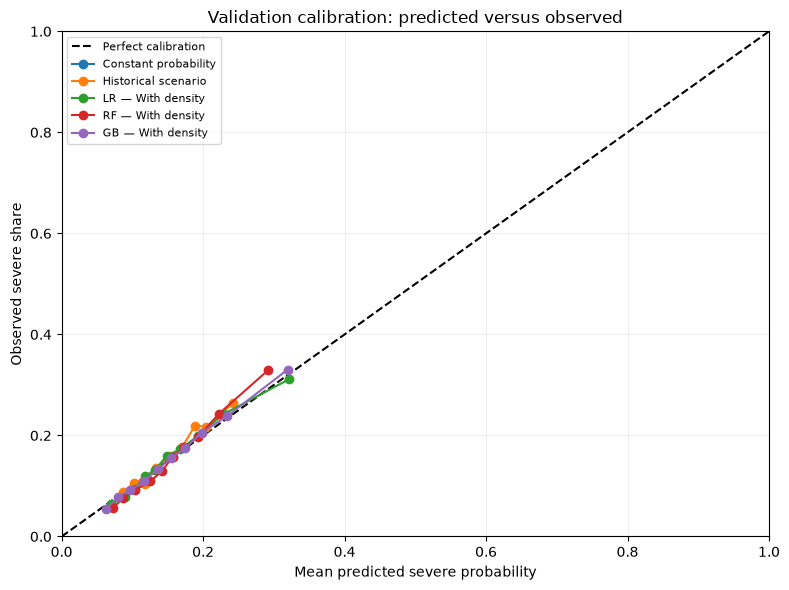

Quantile bins contain roughly equal numbers of accidents; tied predictions can reduce the bin count.


In [117]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
for name, probabilities in validation_predictions.items():
    observed, predicted = calibration_curve(y_val, probabilities, n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, marker="o", label=name)
ax.set(xlabel="Mean predicted severe probability", ylabel="Observed severe share",
       title="Validation calibration: predicted versus observed", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print("Quantile bins contain roughly equal numbers of accidents; tied predictions can reduce the bin count.")

### What we observed

- All models stay close to the diagonal line, so their predicted percentages roughly match what really happened.
- Predictions range from about 5% to 33%. No model claims an accident is almost certainly serious, which makes sense because chance plays a big part in how badly people are hurt.
- At the high end, Random Forest predicts slightly too low and Logistic Regression flattens out slightly. GB stays closest to the line across the whole range.

### What we do next

The overall picture looks good, but averages can hide problems. Next we run an **error analysis** on the current leader (GB) to see whether some groups of accidents are predicted too high or too low.

### Error Analysis — Where are the probabilities less reliable?

The table below checks the current validation AP leader across states, day/night and road-user involvement. It shows group size, actual severe share, average predicted probability and probability error. Groups can overlap. Small groups deserve caution.

This uses the validation set only. It is not a final model choice or a test result. A positive prediction gap means the model predicts too many severe outcomes on average in that group.

In [118]:
review_name = all_model_results.loc[all_model_results["AP"].idxmax(), "model"]
review_rows = validation[["state", "hour", "severe"] + binary_features].copy()
review_rows["probability"] = validation_predictions[review_name]
review_rows["nighttime"] = (review_rows["hour"] >= 22) | (review_rows["hour"] < 6)
error_rows = []
for group_column in ["state", "nighttime"] + binary_features:
    for group_value, part in review_rows.groupby(group_column, observed=True):
        error_rows.append({
            "group": group_column, "value": group_value, "accidents": len(part),
            "actual_severe_pct": 100 * part["severe"].mean(),
            "predicted_severe_pct": 100 * part["probability"].mean(),
            "gap_percentage_points": 100 * (part["probability"].mean() - part["severe"].mean()),
            "Brier": brier_score_loss(part["severe"], part["probability"]),
        })
error_summary = pd.DataFrame(error_rows)
print("Reviewing:", review_name)
with pd.option_context("display.max_rows", None):
    display(error_summary.round(4))

Reviewing: GB — With density


,group,value,accidents,actual_severe_pct,predicted_severe_pct,gap_percentage_points,Brier
0,state,1,1735,14.0058,13.7749,-0.2309,0.1168
1,state,2,1055,9.4787,8.6282,-0.8505,0.0845
2,state,3,3755,14.7004,15.2040,0.5036,0.1183
3,state,4,377,10.0796,8.0458,-2.0338,0.0874
4,state,5,9332,14.8414,14.6956,-0.1458,0.1222
5,state,6,2789,14.5930,15.1513,0.5582,0.1175
6,state,7,1907,18.1437,17.2406,-0.9031,0.1405
7,state,8,4696,15.6729,15.3646,-0.3083,0.1255
8,state,9,7028,16.5766,16.8119,0.2353,0.1296
9,state,10,503,16.8986,15.5382,-1.3604,0.1367


### What we observed

- For most groups, the predicted and real serious-injury shares differ by **less than 1 percentage point**. This includes night versus day and every road-user group.
- The model picks up the big real differences well. Motorcycle accidents are about 25% serious, and it predicts 24.4%. Night accidents are about 20% serious, and it predicts 20.2%.
- The largest misses are in a few **states**. Brandenburg is predicted about 3 points too high. Bremen is about 2 points too low and Saarland about 1.4 points too low. Bremen and Saarland are small groups, so their numbers are less certain.

### What we do next

The models still use starting settings, so we try to **improve them by tuning**. We test a few settings for each model with cross-validation on the training data only, then compare the tuned and original versions on validation.

## Improve the models using training data only

We try a small, planned set of settings for all three methods, each with population density. **Cross-validation** means dividing training data into three parts: learn from two parts and check the third, then repeat until every part has been checked. Each fold learns its own input preparation, so held-out rows cannot influence those steps.

We choose settings by average **AP**, because finding severe accidents near the top of a ranked list matters here. We also record ROC-AUC and Brier. The settings below are a limited search, not proof that we found the best possible model. We keep the same folds for every candidate. The validation set is not used in this search.

After searching, we fit each winner on all training rows and compare its validation predictions with the original models and benchmarks. We choose the fitted model with the highest validation AP, using Brier to break exact ties. Calibration then checks whether a probability adjustment improves Brier. This is our stated selection rule, not a client-approved operating threshold.

In [119]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

training_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {
    "AP": "average_precision",
    "ROC_AUC": "roc_auc",
    "neg_Brier": "neg_brier_score",
}
# Each family has three settings, including the starting configuration.
search_grids = {
    "LR": {"model__C": [0.1, 1.0, 10.0]},
    "RF": [
        {"model__max_depth": [15], "model__min_samples_leaf": [50]},
        {"model__max_depth": [12], "model__min_samples_leaf": [100]},
        {"model__max_depth": [None], "model__min_samples_leaf": [20]},
    ],
    "GB": [
        {"model__max_leaf_nodes": [15], "model__min_samples_leaf": [50], "model__l2_regularization": [1.0]},
        {"model__max_leaf_nodes": [7], "model__min_samples_leaf": [100], "model__l2_regularization": [1.0]},
        {"model__max_leaf_nodes": [31], "model__min_samples_leaf": [50], "model__l2_regularization": [5.0]},
    ],
}
fitted_candidates = {
    "LR — With density": (lr_density, X_train_density, X_val_density),
    "RF — With density": (rf_density_pipeline, X_train_density, X_val_density),
    "GB — With density": (gb_density_pipeline, X_train_density, X_val_density),
}
searches = {}
cv_tables = []
cv_winners = []
# Snapshot the three original candidates before adding tuned candidates.
for name, (pipeline, training_inputs, validation_inputs) in list(fitted_candidates.items()):
    family = name.split(" — ")[0]
    estimator = clone(pipeline)
    if family == "RF":
        estimator.set_params(model__n_jobs=2)
    search = GridSearchCV(
        estimator, search_grids[family], scoring=scoring, refit="AP",
        cv=training_cv, n_jobs=1, error_score="raise", return_train_score=False,
    )
    search.fit(training_inputs, y_train)
    searches[name] = search
    table = pd.DataFrame(search.cv_results_)
    cv_tables.append(pd.DataFrame({
        "model": name,
        "settings": table["params"].astype(str),
        "CV_AP": table["mean_test_AP"],
        "CV_AP_sd": table["std_test_AP"],
        "CV_ROC_AUC": table["mean_test_ROC_AUC"],
        "CV_Brier": -table["mean_test_neg_Brier"],
        "AP_rank": table["rank_test_AP"],
    }))
    tuned_name = "Tuned " + name
    fitted_candidates[tuned_name] = (search.best_estimator_, training_inputs, validation_inputs)
    validation_predictions[tuned_name] = search.predict_proba(validation_inputs)[:, 1]
    cv_winners.append({"model": tuned_name, "best_settings": str(search.best_params_), "CV_AP": search.best_score_})
    print(f"Finished {name}: best training CV AP = {search.best_score_:.5f}", flush=True)
cv_results = pd.concat(cv_tables, ignore_index=True)
display(cv_results.round(5))
display(pd.DataFrame(cv_winners).round(5))
print("Fold variation is descriptive; it is not a confidence interval.")

Finished LR — With density: best training CV AP = 0.25376
Finished RF — With density: best training CV AP = 0.26211
Finished GB — With density: best training CV AP = 0.26521


,model,settings,CV_AP,CV_AP_sd,CV_ROC_AUC,CV_Brier,AP_rank
0,LR — With density,{'model__C': 0.1},0.25375,0.00288,0.65049,0.12721,2
1,LR — With density,{'model__C': 1.0},0.25374,0.00290,0.65047,0.12721,3
2,LR — With density,{'model__C': 10.0},0.25376,0.00289,0.65050,0.12721,1
3,RF — With density,"{'model__max_depth': 15, 'model__min_samples_l...",0.26211,0.00207,0.65950,0.12663,1
4,RF — With density,"{'model__max_depth': 12, 'model__min_samples_l...",0.26045,0.00217,0.65845,0.12688,3
5,RF — With density,"{'model__max_depth': None, 'model__min_samples...",0.26116,0.00173,0.65776,0.12659,2
6,GB — With density,"{'model__l2_regularization': 1.0, 'model__max_...",0.26493,0.00173,0.66261,0.12624,2
7,GB — With density,"{'model__l2_regularization': 1.0, 'model__max_...",0.26402,0.00242,0.66087,0.12638,3
8,GB — With density,"{'model__l2_regularization': 5.0, 'model__max_...",0.26521,0.00142,0.66312,0.12620,1


,model,best_settings,CV_AP
0,Tuned LR — With density,{'model__C': 10.0},0.25376
1,Tuned RF — With density,"{'model__max_depth': 15, 'model__min_samples_l...",0.26211
2,Tuned GB — With density,"{'model__l2_regularization': 5.0, 'model__max_...",0.26521


Fold variation is descriptive; it is not a confidence interval.


### What we observed

- **LR:** all three values of C score practically the same (CV AP about 0.2537). C = 10 wins by a tiny margin, so the strength setting hardly matters.
- **RF:** the original setting (depth 15, leaf size 50) wins (CV AP 0.262).
- **GB:** a **new setting wins**: larger trees (31 leaves) with stronger regularization (l2 = 5.0), CV AP **0.2652** versus 0.2649 for the original. The difference is tiny, smaller than the variation between folds (about ±0.0014–0.0029).
- The settings we tried matter much less than the choice of model. GB still has the best cross-validation score, which matches what we saw on validation.

### What we do next

We put the tuned versions next to the originals and compare all of them on the same validation accidents. Then we pick one model using our rule: highest AP, with Brier breaking any tie.

### Compare the original and tuned models

This table includes the two benchmarks, three original fitted models and three tuned versions (all with density). A tuned version can choose the same settings as its starting model; it is not a new algorithm.

We use the same validation accidents for every row. Tuning is not guaranteed to improve validation performance. We retain the original candidates rather than assuming a tuned model must win.

,model,AP,ROC_AUC,Brier
7,Tuned GB — With density,0.27245,0.66875,0.12570
4,GB — With density,0.27179,0.66836,0.12576
3,RF — With density,0.26847,0.66733,0.12614
6,Tuned RF — With density,0.26847,0.66733,0.12614
2,LR — With density,0.25940,0.65602,0.12681
5,Tuned LR — With density,0.25935,0.65602,0.12681
1,Historical scenario,0.22556,0.62163,0.12916
0,Constant probability,0.15705,0.50000,0.13239


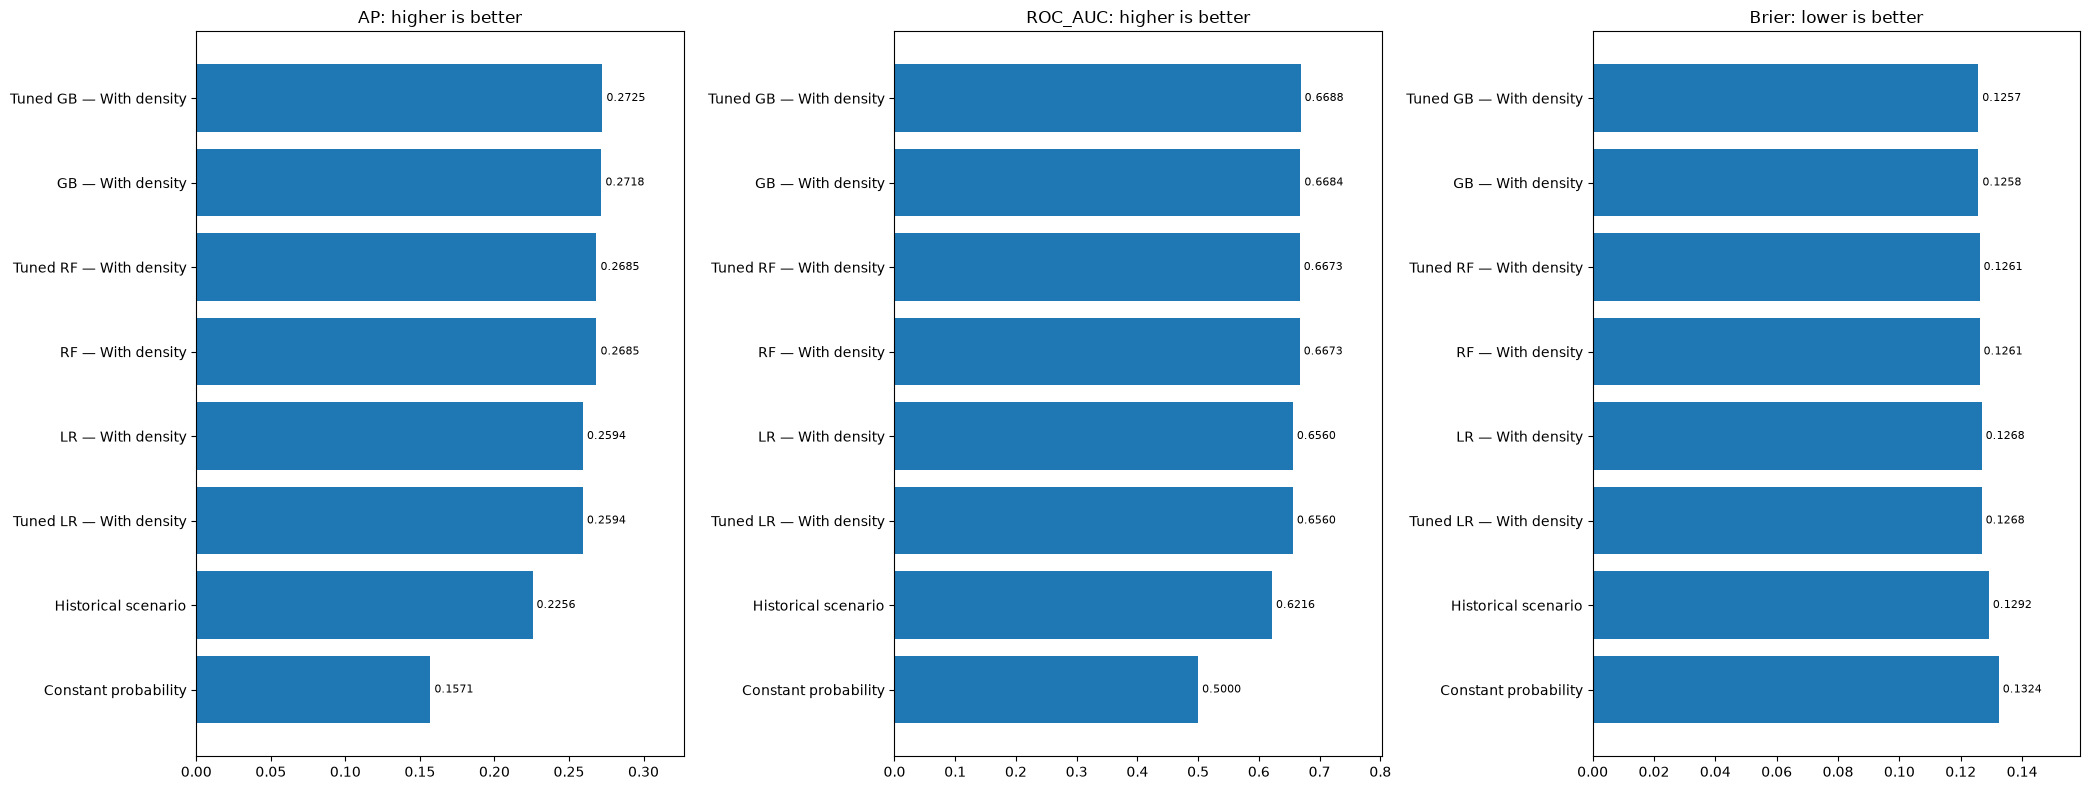

AP leader among fitted models: Tuned GB — With density
Selected settings: {'categorical_features': None, 'class_weight': None, 'early_stopping': False, 'interaction_cst': None, 'l2_regularization': 5.0, 'learning_rate': 0.05, 'loss': 'log_loss', 'max_bins': 255, 'max_depth': None, 'max_features': 1.0, 'max_iter': 200, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'monotonic_cst': None, 'n_iter_no_change': 10, 'random_state': 42, 'scoring': 'loss', 'tol': 1e-07, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


In [120]:
all_model_results = pd.DataFrame([
    validation_scores(name, probabilities)
    for name, probabilities in validation_predictions.items()
])
display(all_model_results.sort_values(["AP", "Brier"], ascending=[False, True]).round(5))
fig, axes = plt.subplots(1, 3, figsize=(21, 8))
for ax, metric in zip(axes, ["AP", "ROC_AUC", "Brier"]):
    ordered = all_model_results.sort_values(metric, ascending=(metric != "Brier"))
    ax.barh(ordered["model"], ordered[metric])
    ax.set_title(f"{metric}: {'lower' if metric == 'Brier' else 'higher'} is better")
    ax.set_xlim(0, ordered[metric].max() * 1.2)
    for i, value in enumerate(ordered[metric]):
        ax.text(value, i, f" {value:.4f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

eligible = all_model_results[all_model_results["model"].isin(fitted_candidates)]
selection_row = eligible.sort_values(["AP", "Brier"], ascending=[False, True]).iloc[0]
selected_name = selection_row["model"]
selected_model, selected_X_train, selected_X_val = fitted_candidates[selected_name]
selected_raw_probabilities = validation_predictions[selected_name]
print("AP leader among fitted models:", selected_name)
print("Selected settings:", selected_model.named_steps["model"].get_params())

### What we observed

- **Tuned GB** (31 leaves, l2 = 5.0) is now slightly better than the original GB on validation: AP **0.2725** vs 0.2718, Brier **0.12570** vs 0.12576. ROC-AUC is about the same (0.6688 vs 0.6684).
- Tuned RF is identical to the original, because tuning picked the original settings. Tuned LR is practically identical (AP 0.2594 vs 0.2594).
- The ranking is: **Tuned GB (0.272) ≈ GB (0.272) > RF (0.268) > LR (0.259)** > Historical guess (0.226) > Constant guess (0.157).
- **Tuned GB with density** has the highest AP, so our rule selects it. It also has the best ROC-AUC and the lowest Brier of all models.
- The gain from tuning is very small, so it confirms GB as the best model family more than it creates a much better model.

### What we do next

GB ranks accidents best, but we also want its percentages to be as accurate as possible. Next we test whether a small **calibration** adjustment makes its predicted chances closer to reality.

## Calibrate the selected model's probabilities

A model can rank accidents well but give percentages that are too high or too low. **Calibration** learns a small adjustment to those percentages.

We try one smooth adjustment called sigmoid calibration. It learns from training predictions made on held-out training folds, not validation labels. The underlying model is refitted on all training rows. We compare adjusted and original probabilities on validation, keeping the version with lower Brier score. If the scores tie, we keep the original.

This adds another validation-based choice, so the final test remains necessary later. The adjustment is intended to improve percentages, not discover a new ranking model.

,model,AP,ROC_AUC,Brier
0,Tuned GB — With density,0.272452,0.668753,0.125701
1,Tuned GB — With density + sigmoid calibration,0.272452,0.668753,0.125694


Selected probability version: Tuned GB — With density + sigmoid calibration


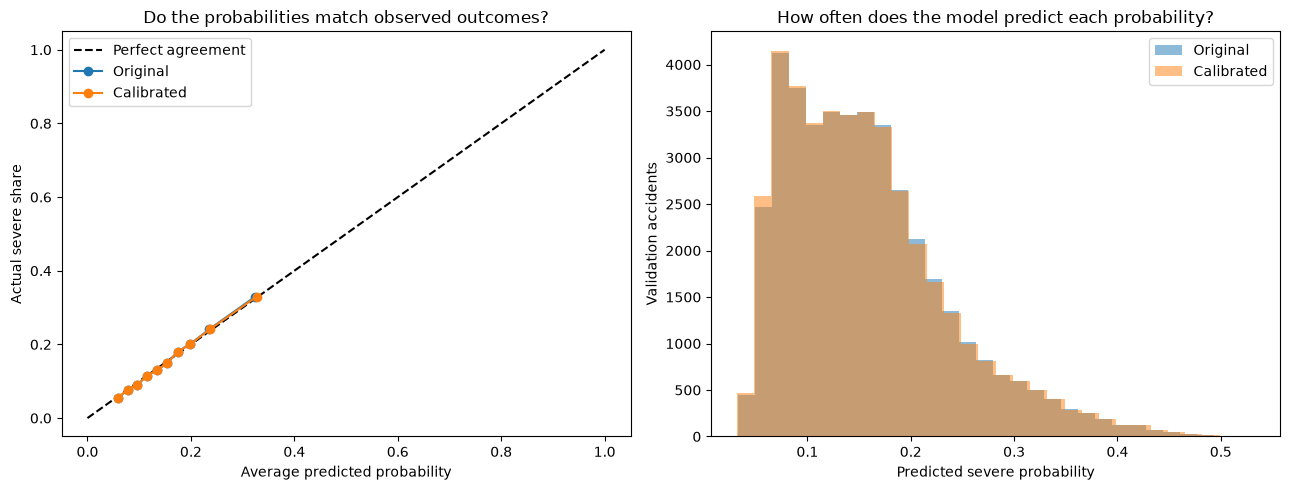

,accidents,predicted_probability,actual_severe_share,gap_percentage_points
bin,,,,
"(0.030899999999999997, 0.0694]",4095,0.05907,0.05543,0.36387
"(0.0694, 0.0859]",4090,0.07746,0.07751,-0.00464
"(0.0859, 0.105]",4092,0.09524,0.09018,0.50648
"(0.105, 0.125]",4092,0.11512,0.11510,0.00170
"(0.125, 0.144]",4092,0.13456,0.13050,0.40625
"(0.144, 0.164]",4092,0.15435,0.14956,0.47852
"(0.164, 0.185]",4092,0.17437,0.18011,-0.57398
"(0.185, 0.215]",4092,0.19892,0.20064,-0.17130
"(0.215, 0.266]",4092,0.23704,0.24145,-0.44073


In [121]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

calibrated_candidate = CalibratedClassifierCV(
    estimator=clone(selected_model), method="sigmoid", cv=training_cv,
    ensemble=False, n_jobs=1,
)
calibrated_candidate.fit(selected_X_train, y_train)
p_calibrated = calibrated_candidate.predict_proba(selected_X_val)[:, 1]
calibration_results = pd.DataFrame([
    validation_scores(selected_name, selected_raw_probabilities),
    validation_scores(selected_name + " + sigmoid calibration", p_calibrated),
])
display(calibration_results.round(6))
use_calibrated = calibration_results.iloc[1]["Brier"] < calibration_results.iloc[0]["Brier"]
final_model = calibrated_candidate if use_calibrated else selected_model
final_model_name = selected_name + (" + sigmoid calibration" if use_calibrated else "")
p_final_validation = p_calibrated if use_calibrated else selected_raw_probabilities
print("Selected probability version:", final_model_name)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot([0, 1], [0, 1], "k--", label="Perfect agreement")
for name, probabilities in [("Original", selected_raw_probabilities), ("Calibrated", p_calibrated)]:
    observed, predicted = calibration_curve(y_val, probabilities, n_bins=10, strategy="quantile")
    axes[0].plot(predicted, observed, marker="o", label=name)
    axes[1].hist(probabilities, bins=30, alpha=0.5, label=name)
axes[0].set(xlabel="Average predicted probability", ylabel="Actual severe share", title="Do the probabilities match observed outcomes?")
axes[1].set(xlabel="Predicted severe probability", ylabel="Validation accidents", title="How often does the model predict each probability?")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

calibration_rows = pd.DataFrame({"actual": y_val.to_numpy(), "probability": p_final_validation})
calibration_rows["bin"] = pd.qcut(calibration_rows["probability"], q=10, duplicates="drop")
calibration_table = calibration_rows.groupby("bin", observed=True).agg(
    accidents=("actual", "size"), predicted_probability=("probability", "mean"), actual_severe_share=("actual", "mean"),
)
calibration_table["gap_percentage_points"] = 100 * (calibration_table["predicted_probability"] - calibration_table["actual_severe_share"])
display(calibration_table.round(5))

### What we observed

- Calibration lowered the Brier score by a tiny amount, **from 0.125701 to 0.125694**, so by our rule we keep the calibrated version.
- **AP and ROC-AUC did not change** (0.2725 and 0.6688). That's expected: calibration adjusts the percentages but keeps the order of accidents the same.
- In all 10 probability bands, the predicted share and the real share differ by **less than 0.6 percentage points**. When the model says about 20%, about 20% of those accidents really are serious.
- The improvement is extremely small, so we don't claim calibration made a real difference. Tuned GB was already well calibrated.

### What we do next

Overall the percentages are trustworthy. Next we check whether this is also true **for individual groups**: states, night and day, weekends, density levels and road users.

## Group error analysis for the selected model

An acceptable overall score can hide weaker predictions for some groups. We check states, night versus other hours, weekends, every road-user flag and population-density groups. Density boundaries come from training data only.

The table shows the number of accidents, severe count, actual and predicted percentages, and Brier error. Positive gaps mean predictions are too high on average. We flag groups below 200 accidents for caution; 200 is a practical display rule, not a guarantee that a result is reliable. Road-user groups overlap. These are descriptive checks, not proof that one group is treated fairly or that differences are statistically certain.

,group,value,accidents,severe_accidents,actual_severe_pct,predicted_severe_pct,gap_percentage_points,Brier,small_group
0,state_name,Baden-Württemberg,4696,736,15.6729,15.3442,-0.3287,0.1256,False
1,state_name,Bayern,7028,1165,16.5766,16.8283,0.2517,0.1296,False
2,state_name,Berlin,1976,233,11.7915,12.4480,0.6565,0.1029,False
3,state_name,Brandenburg,1278,191,14.9452,17.8790,2.9338,0.1230,False
4,state_name,Bremen,377,38,10.0796,7.8001,-2.2795,0.0877,False
5,state_name,Hamburg,1055,100,9.4787,8.2977,-1.1810,0.0851,False
6,state_name,Hessen,2789,407,14.5930,15.1303,0.5372,0.1176,False
7,state_name,Mecklenburg-Vorpommern,729,141,19.3416,19.2954,-0.0461,0.1482,False
8,state_name,Niedersachsen,3755,552,14.7004,15.2239,0.5235,0.1183,False
9,state_name,Nordrhein-Westfalen,9332,1385,14.8414,14.7440,-0.0974,0.1219,False


Five largest average probability gaps among groups with at least 200 accidents:


,group,value,accidents,severe_accidents,actual_severe_pct,predicted_severe_pct,gap_percentage_points,Brier,small_group,absolute_gap
3,state_name,Brandenburg,1278,191,14.9452,17.8790,2.9338,0.1230,False,2.9338
4,state_name,Bremen,377,38,10.0796,7.8001,-2.2795,0.0877,False,2.2795
15,state_name,Thüringen,806,182,22.5806,23.8898,1.3092,0.1665,False,1.3092
11,state_name,Saarland,503,85,16.8986,15.6088,-1.2898,0.1363,False,1.2898
5,state_name,Hamburg,1055,100,9.4787,8.2977,-1.1810,0.0851,False,1.1810


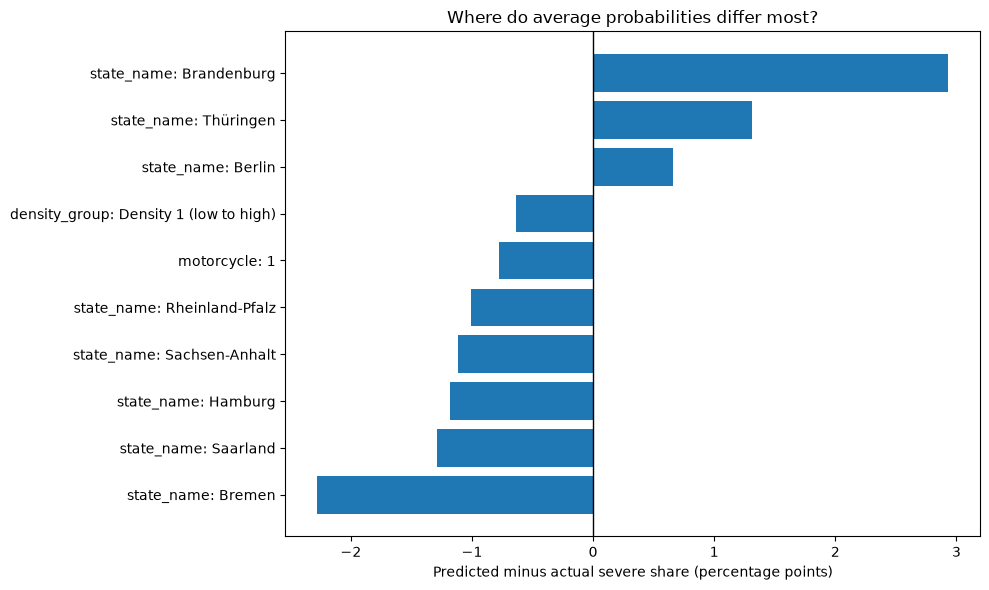

In [122]:
group_rows = validation[["state_name", "hour", "weekday", "population_per_km2", "severe"] + binary_features].copy()
group_rows["probability"] = p_final_validation
group_rows["nighttime"] = np.where((group_rows["hour"] >= 22) | (group_rows["hour"] < 6), "Night", "Other hours")
group_rows["weekend"] = np.where(group_rows["weekday"].str.strip().str.lower().isin(weekend_names), "Weekend", "Weekday")
_, training_density_edges = pd.qcut(train["population_per_km2"], q=5, retbins=True, duplicates="drop")
training_density_edges[0], training_density_edges[-1] = -np.inf, np.inf
group_rows["density_group"] = pd.cut(
    group_rows["population_per_km2"], training_density_edges,
    labels=[f"Density {i + 1} (low to high)" for i in range(len(training_density_edges) - 1)],
    include_lowest=True,
)
final_error_rows = []
for group_column in ["state_name", "nighttime", "weekend", "density_group"] + binary_features:
    for group_value, part in group_rows.groupby(group_column, observed=True):
        actual_share = part["severe"].mean()
        predicted_share = part["probability"].mean()
        final_error_rows.append({
            "group": group_column, "value": str(group_value), "accidents": len(part),
            "severe_accidents": int(part["severe"].sum()),
            "actual_severe_pct": 100 * actual_share,
            "predicted_severe_pct": 100 * predicted_share,
            "gap_percentage_points": 100 * (predicted_share - actual_share),
            "Brier": brier_score_loss(part["severe"], part["probability"]),
            "small_group": len(part) < 200,
        })
final_error_summary = pd.DataFrame(final_error_rows)
with pd.option_context("display.max_rows", None):
    display(final_error_summary.round(4))
reliable_size_groups = final_error_summary.loc[~final_error_summary["small_group"]].copy()
reliable_size_groups["absolute_gap"] = reliable_size_groups["gap_percentage_points"].abs()
print("Five largest average probability gaps among groups with at least 200 accidents:")
display(reliable_size_groups.nlargest(5, "absolute_gap").round(4))
fig, ax = plt.subplots(figsize=(10, 6))
plot_groups = reliable_size_groups.nlargest(10, "absolute_gap").sort_values("gap_percentage_points")
ax.barh(plot_groups["group"] + ": " + plot_groups["value"], plot_groups["gap_percentage_points"])
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Predicted minus actual severe share (percentage points)", title="Where do average probabilities differ most?")
plt.tight_layout()
plt.show()

### What we observed

- Outside the states, every group's predicted and real serious shares differ by **less than 1 percentage point**. This includes night and day, weekday and weekend, every road-user group and all five density levels.
- The model picks up the density pattern well: from countryside to city, the real serious share falls from **24.5% to 10.6%**, and the predictions follow closely (23.8% to 10.8%).
- It also gets the high-risk groups right. Motorcycle accidents are 25.4% serious, and the model predicts 24.6%. Night accidents are 20.0% serious, and it predicts 20.4%.
- The largest misses are in a few **states**:
  - **Brandenburg:** predicted too high by about 2.9 points (17.9% vs 14.9%).
  - **Bremen:** predicted too low by about 2.3 points (7.8% vs 10.1%).
  - **Thüringen:** predicted too high by about 1.3 points (23.9% vs 22.6%).
  - **Saarland:** predicted too low by about 1.3 points (15.6% vs 16.9%).
  - **Hamburg:** predicted too low by about 1.2 points (8.3% vs 9.5%).
- Bremen and Saarland have only a few hundred accidents, so their gaps are less certain. These are areas to look into, not proof that something is wrong.

### What we do next

We have a final candidate: **Tuned GB with density + sigmoid calibration**. Next we freeze it, report how it compares with the baselines, and later run **one final check on the locked test set**.

## Final model choice — based on validation, not the final test

The following report names the selected model and its settings, explains the calibration decision and compares its probabilities with both benchmarks. This is the model selected for the later final test, not a claim that deployment is approved.

No classification threshold has been selected: the product currently returns probabilities. False-positive/false-negative counts depend on a threshold and client costs, which have not been agreed.

In [123]:
final_validation_result = validation_scores(final_model_name, p_final_validation)
print("MODEL SELECTED FOR THE FINAL TEST:", final_model_name)
display(pd.DataFrame([final_validation_result]).round(6))
for baseline_name in ["Constant probability", "Historical scenario"]:
    baseline_row = all_model_results.set_index("model").loc[baseline_name]
    print(f"\nCompared with {baseline_name}:")
    print(f"AP change: {final_validation_result['AP'] - baseline_row['AP']:+.5f}")
    print(f"ROC-AUC change: {final_validation_result['ROC_AUC'] - baseline_row['ROC_AUC']:+.5f}")
    print(f"Brier change: {final_validation_result['Brier'] - baseline_row['Brier']:+.5f}")
print("\nCalibration retained:", use_calibrated)
print("Final test predictions and scores: NOT calculated.")
print("No model was refitted using validation rows. The selection is now ready for a later final test.")


MODEL SELECTED FOR THE FINAL TEST: Tuned GB — With density + sigmoid calibration


,model,AP,ROC_AUC,Brier
0,Tuned GB — With density + sigmoid calibration,0.272452,0.668753,0.125694



Compared with Constant probability:
AP change: +0.11540
ROC-AUC change: +0.16875
Brier change: -0.00669

Compared with Historical scenario:
AP change: +0.04689
ROC-AUC change: +0.04712
Brier change: -0.00346

Calibration retained: True
Final test predictions and scores: NOT calculated.
No model was refitted using validation rows. The selection is now ready for a later final test.


## Summary for the client — the model selected for the final test

**Selected approach:** Tuned GB — With density + sigmoid calibration (31 leaves per tree, at least 50 accidents per leaf, l2 regularization 5.0, 200 rounds, learning rate 0.05).

We completed three-fold cross-validation on training data for all three algorithms, each using population density and cyclic (sine/cosine) hour and month. Each search tried three settings. We then compared all original and tuned versions on the same validation accidents.

The fitted model was selected by highest validation AP, with Brier as an exact-tie breaker. We then compared its original and calibrated probabilities and kept the lower-Brier version. Calibration was learned from training folds only. **Calibration retained: yes.** Its validation Brier improvement is tiny: approximately 0.000007. Ranking scores are unchanged. This is not evidence of a large or statistically established improvement.

| Approach | AP (higher is better) | ROC-AUC (higher is better) | Brier (lower is better) |
| --- | ---: | ---: | ---: |
| Constant probability | 0.15705 | 0.50000 | 0.13239 |
| Historical scenario | 0.22556 | 0.62163 | 0.12916 |
| Selected model | 0.27245 | 0.66875 | 0.12569 |

AP is a ranking score, not accuracy or the percentage of severe accidents we detect. Brier measures probability error. Better scores than the benchmarks show added value on this validation split; they do not guarantee usefulness for every location or a future year.

**Where predictions still need care:** the largest average probability gaps among inspected groups with at least 200 accidents were:

- state_name: Brandenburg — 1,278 accidents; predicted 17.88% versus observed 14.95% (+2.93 percentage points).
- state_name: Bremen — 377 accidents; predicted 7.80% versus observed 10.08% (-2.28 percentage points).
- state_name: Thüringen — 806 accidents; predicted 23.89% versus observed 22.58% (+1.31 percentage points).

These group comparisons overlap and have sampling uncertainty. They identify areas to investigate; they do not prove a cause or certify fairness. The calibration table above also shows differences across probability ranges.

**What is finished:** data checks, baselines, three algorithms, a limited training-only setting search, validation comparisons, calibration checks, group error analysis and a model choice.

**What remains:** a single final test evaluation after freezing this choice, any client-approved decision threshold, saving a deployable model, and the presentation. The final test predictions and scores have not been calculated. No model has learned from validation rows.

### Metric leaders before calibration

The next cell lists the metric leaders before calibration and compares them with the benchmarks. The model choice and calibrated scores above are the final decision for this development stage.

In [124]:
# Explain the findings from the actual validation results
results = all_model_results.set_index("model")

best_ap = all_model_results.loc[all_model_results['AP'].idxmax()]
best_auc = all_model_results.loc[all_model_results['ROC_AUC'].idxmax()]
best_brier = all_model_results.loc[all_model_results['Brier'].idxmin()]
print("Best validation AP:", best_ap['model'], f"({best_ap['AP']:.4f})")
print("Best validation ROC-AUC:", best_auc['model'], f"({best_auc['ROC_AUC']:.4f})")
print("Lowest validation Brier:", best_brier['model'], f"({best_brier['Brier']:.4f})")
print("\nThese are validation findings, not final test results.")
print("\nComparison of each metric leader with the benchmarks:")
for baseline_name in ["Constant probability", "Historical scenario"]:
    benchmark = results.loc[baseline_name]
    print(f"\nAgainst {baseline_name}:")
    print(f"  Best AP change: {best_ap['AP'] - benchmark['AP']:+.4f}")
    print(f"  Best ROC-AUC change: {best_auc['ROC_AUC'] - benchmark['ROC_AUC']:+.4f}")
    print(f"  Lowest Brier change: {best_brier['Brier'] - benchmark['Brier']:+.4f}")
print("Positive AP/AUC changes and negative Brier changes are improvements.")
print("Different metrics may favour different approaches; no test-based choice was made.")

Best validation AP: Tuned GB — With density (0.2725)
Best validation ROC-AUC: Tuned GB — With density (0.6688)
Lowest validation Brier: Tuned GB — With density (0.1257)

These are validation findings, not final test results.

Comparison of each metric leader with the benchmarks:

Against Constant probability:
  Best AP change: +0.1154
  Best ROC-AUC change: +0.1688
  Lowest Brier change: -0.0067

Against Historical scenario:
  Best AP change: +0.0469
  Best ROC-AUC change: +0.0471
  Lowest Brier change: -0.0035
Positive AP/AUC changes and negative Brier changes are improvements.
Different metrics may favour different approaches; no test-based choice was made.


### How to explain our results to the team

1. **We first checked all the accident circumstances** — time, month, weekend, lighting, road surface, road users, federal state and place. We compared severe-injury **percentages**, not only counts.
2. **We added a geographical clue:** municipality population density. We also compared density patterns within road-user groups.
3. **We added two benchmarks:** a fixed training-rate probability and smoothed training scenario rates.
4. **We compared three algorithms:** Logistic Regression, Random Forest and Gradient Boosting, all using the same scenario inputs (with cyclic sine/cosine hour and month) plus population density. The tuned candidates are evaluated above.
5. **We compared validation probabilities** using AP (ranking serious accidents), ROC-AUC (separating classes) and Brier (probability error). The code above reports the actual scores and best-performing models.

These are patterns among **recorded injury accidents**. They do not tell us how likely an accident is to occur, prove causation, or guarantee the same results in a new year. Our split is our own 70/15/15 split, which might differ from a teammate's split. **The final test data is reserved.**

## Assignment Check — What Is Finished and What Remains?

| Requirement | Current position |
| --- | --- |
| Clear question, proposed client and possible value | Described above; confirm usefulness with a real stakeholder |
| Class imbalance | Checked; about 15.7% of recorded injury accidents are severe |
| Simple baseline | Both benchmarks calculated on validation data |
| At least three different algorithms | **Three implemented:** Logistic Regression, Random Forest and Gradient Boosting; all three methods are run on the project data above |
| Cross-validation | Three training-only folds used for all three searches |
| Model-setting search (hyperparameter tuning) | Three candidate settings per algorithm; 27 cross-validation fits plus refits |
| Error analysis | Training/validation checks, calibration comparison and selected-model group checks completed above |
| Final test evaluation | Deliberately reserved until model choices are fixed |
| Save and reuse a chosen model | Model selected for a later final test; deployment and model export remain separate steps |
| Client presentation and possible data product | Prepare the separate 10-minute presentation and product slide |
| GitHub delivery | Save the notebooks and presentation in the team repository |

The assignment also requests milestone tracking on a GitHub board, a slide draft, and well-documented reproducible code. These notebooks do not verify the board or complete the presentation. Keep each remaining item visible rather than claiming the whole assignment is finished.

## Potential Data Product

A possible tool could let a road-safety analyst enter an accident scenario and see an estimated serious/fatal share, alongside the model's limits. It should support investigation, not automatically decide spending or claim how many accidents a policy would prevent. Validate the intended use with the client first.

## Next Steps: Final Check, Save and Reuse

The training-only searches and validation-based model choice have been completed. Next, freeze this choice and run one final test evaluation. Agree any decision threshold with the client separately. The reference saves and reloads a model; here that comes after the final choice, so we do not save an arbitrary winner prematurely.

## References and Project Notes

Structure: supplied `03_eda-and-modeling(2).ipynb`. Assignment: supplied `01_assignment(2).md`. Analysis and saved scores: the attached updated Accident Atlas notebook. Baseline definitions: the agreed project instructions. Earlier historical-baseline code was not supplied, so exact equivalence to that older implementation has not been verified.

## Final Summary

### What we wanted to know
When an injury accident happens, how likely is it that someone is **seriously injured or killed**? Our model gives a **probability**, not a yes/no answer, to help a road-safety team spot situations that deserve a closer look.

### What we did
1. **Checked the data:** 272,812 accidents from 2025, with no duplicates or missing values. About **16 in 100** are serious or fatal.
2. **Split the data:** 70% training, 15% validation and 15% test. The test set stays locked for one final check.
3. **Chose 17 inputs:** place, cyclic time (sine/cosine of hour and month), lighting, road surface, the road users involved and **municipality population density**. We left out anything that would give away the answer.
4. **Built two simple baselines to beat:** the same 16% for every accident, and a lookup of similar past scenarios.
5. **Trained three models:** Logistic Regression, Random Forest and Gradient Boosting.
6. **Tuned the settings** with 3-fold cross-validation on training data only.
7. **Picked the winner** by validation AP, then **calibrated** its probabilities and checked its errors group by group.

### Results (validation data)

| Approach | AP ↑ | ROC-AUC ↑ | Brier ↓ |
| --- | ---: | ---: | ---: |
| Constant guess | 0.1571 | 0.5000 | 0.1324 |
| Historical scenario | 0.2256 | 0.6216 | 0.1292 |
| Logistic Regression | 0.2594 | 0.6560 | 0.1268 |
| Random Forest | 0.2685 | 0.6673 | 0.1261 |
| Gradient Boosting (original settings) | 0.2718 | 0.6684 | 0.1258 |
| **Tuned Gradient Boosting + calibration** | **0.2725** | **0.6688** | **0.1257** |

### Why Gradient Boosting was selected
- **Best on all three scores:** it ranks serious accidents highest and gives the most accurate probabilities.
- **Little overfitting:** the original GB's training and validation scores are close (AP 0.283 vs 0.272), while Random Forest shows a bigger gap (0.312 vs 0.268).
- **Learns combinations:** each new tree corrects earlier mistakes, so it picks up risky combinations such as motorcycle + rural area + night.
- **Trustworthy percentages:** after calibration, predicted and real serious shares differ by less than 0.6 percentage points in every probability band.

### Key findings
- **Population density matters:** accidents in the least dense areas are serious about **24.5%** of the time, compared with **10.6%** in the densest. The model follows this pattern closely.
- **Motorcycle and night accidents** have clearly higher serious shares (about 25% and 20%), and the model predicts both well.
- **Cyclic time changed very little:** compared with plain hour and month, every score moved by less than 0.001. Lighting (daylight, dusk, dark) probably already carries most of the time-of-day information.
- **Tuning helped only slightly:** a GB setting with larger trees and stronger regularization edged out the original.
- **The largest prediction gaps are in a few states**: Brandenburg is predicted about 2.9 points too high and Bremen about 2.3 points too low.

### Limitations
- The improvement over the baselines is real but **modest**. Chance plays a big part in how badly people are hurt.
- These scores come from **validation data**. The final test hasn't been run yet.
- The model shows **patterns, not causes**. Density describes the whole municipality, not the exact road.
- The data covers one year (2025) and recorded injury accidents only. Results may differ in other years.

### Next steps
1. Freeze the model and run **one final evaluation on the test set**.
2. Agree a decision threshold with the client, if they need one.
3. Save the final model so it can be reused.
4. Present the results and the possible data product: a tool where an analyst enters an accident scenario and sees the estimated chance of serious injury.